# Step 4 — Model Implementation
### Capstone: Detecting Fraudulent Transactions

In [13]:
import os, json, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.metrics import (average_precision_score, roc_auc_score,
    precision_recall_curve, precision_score, recall_score, f1_score,
    fbeta_score, confusion_matrix, classification_report)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
os.makedirs("models", exist_ok=True)
print("Ready.")

Ready.


In [14]:
pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [26]:
pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


## 1. Rebuild preprocessed data (same steps as Step 3)
Load → drop exact duplicates → engineer features → **stratified split** →
RobustScaler **fit on train only**.

In [15]:
df = pd.read_csv("creditcard.csv").drop_duplicates().reset_index(drop=True)

# domain-derived features (identical to Step 3)
df["Hour"] = (df["Time"] // 3600) % 24
df["Log_Amount"] = np.log1p(df["Amount"])
df["Amount_bin"] = pd.qcut(df["Amount"], q=5, labels=False, duplicates="drop")

X = df.drop(columns=["Class"])
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

to_scale = ["Time", "Amount", "Log_Amount", "Hour"]
scaler = RobustScaler()
X_train[to_scale] = scaler.fit_transform(X_train[to_scale])
X_test[to_scale]  = scaler.transform(X_test[to_scale])

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train fraud %%: %.3f | Test fraud %%: %.3f" %
      (y_train.mean()*100, y_test.mean()*100))

Train: (226980, 33) | Test: (56746, 33)
Train fraud %: 0.167 | Test fraud %: 0.167


## 2. Evaluation helpers
`best_threshold` picks the probability cut-off that maximises F2 on the precision-recall
curve. We call it on **training** CV predictions only.

In [16]:
def best_threshold(y_true, y_scores, beta=2.0):
    prec, rec, thr = precision_recall_curve(y_true, y_scores)
    prec, rec = prec[:-1], rec[:-1]            # align with thresholds
    fbeta = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    i = int(np.nanargmax(fbeta))
    return float(thr[i]), float(fbeta[i])

def evaluate(name, y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    return {
        "model": name,
        "AUC_PR":   average_precision_score(y_true, scores),
        "ROC_AUC":  roc_auc_score(y_true, scores),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall":    recall_score(y_true, y_pred),
        "f1":        f1_score(y_true, y_pred, zero_division=0),
        "f2":        fbeta_score(y_true, y_pred, beta=2, zero_division=0),
        "threshold": threshold,
        "tn": cm[0,0], "fp": cm[0,1], "fn": cm[1,0], "tp": cm[1,1],
    }

## 3. Define the supervised models

In [17]:
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
spw = neg / pos    # scale_pos_weight for XGBoost

models = {
    "LogisticRegression": LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "DecisionTree": DecisionTreeClassifier(
        max_depth=8, class_weight="balanced", random_state=RANDOM_STATE),
    "RandomForest": RandomForestClassifier(
        n_estimators=200, max_depth=12, n_jobs=-1,
        class_weight="balanced", random_state=RANDOM_STATE),
}

try:
    from xgboost import XGBClassifier
    models["XGBoost"] = XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1,
        subsample=0.9, colsample_bytree=0.9, eval_metric="aucpr",
        scale_pos_weight=spw, n_jobs=-1, random_state=RANDOM_STATE)
    print("XGBoost available ->", list(models))
except ImportError:
    print("XGBoost not installed (optional). Models:", list(models))

XGBoost available -> ['LogisticRegression', 'DecisionTree', 'RandomForest', 'XGBoost']


## 4. Train, tune threshold (on train CV), evaluate on test
For each model: get out-of-fold probabilities on the training set, choose the F2-best
threshold from them, refit on the full training set, then score the **held-out test set** at
that threshold. The test set is touched only for final evaluation — no leakage.

> Lower `cv` to 3 or shrink `n_estimators` if runtime is an issue.

In [18]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results, fitted, test_scores = [], {}, {}

for name, model in models.items():
    print(f"Training {name} ...")
    # 1) threshold from TRAIN cross-val probabilities
    oof = cross_val_predict(model, X_train, y_train, cv=skf,
                            method="predict_proba", n_jobs=-1)[:, 1]
    thr, _ = best_threshold(y_train, oof, beta=2.0)
    # 2) refit on full train, score test
    model.fit(X_train, y_train)
    s = model.predict_proba(X_test)[:, 1]
    fitted[name] = model
    test_scores[name] = s
    results.append(evaluate(name, y_test, s, thr))

print("Done.")

Training LogisticRegression ...
Training DecisionTree ...
Training RandomForest ...
Training XGBoost ...
Done.


## 5. Unsupervised baseline — Isolation Forest
Trained **without labels** (`contamination` set to the known fraud rate). It usually trails
the supervised models, which is itself a useful finding: labels add a lot of value here.
It has no `predict_proba`, so we use the negative anomaly score and a score-quantile cut-off.

In [19]:
iso = IsolationForest(n_estimators=200, contamination=float(y_train.mean()),
                      random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_train)                                   # labels NOT used
iso_scores = -iso.score_samples(X_test)            # higher = more anomalous
test_scores["IsolationForest"] = iso_scores
fitted["IsolationForest"] = iso

iso_thr = np.quantile(iso_scores, 1 - float(y_train.mean()))
results.append(evaluate("IsolationForest", y_test, iso_scores, iso_thr))
print("Isolation Forest done.")

Isolation Forest done.


## 6. Model comparison
Ranked by **AUC-PR** (our primary metric). This table is a core deliverable.

In [20]:
comparison = (pd.DataFrame(results)
              .sort_values("AUC_PR", ascending=False)
              .reset_index(drop=True))
comparison

,model,AUC_PR,ROC_AUC,precision,recall,f1,f2,threshold,tn,fp,fn,tp
0,XGBoost,0.8169,0.9797,0.9136,0.7789,0.8409,0.8026,0.1984,56644,7,21,74
1,RandomForest,0.7928,0.9656,0.8409,0.7789,0.8087,0.7906,0.3219,56637,14,21,74
2,LogisticRegression,0.6830,0.9683,0.8391,0.7684,0.8022,0.7816,1.0000,56637,14,22,73
3,DecisionTree,0.4971,0.9074,0.0000,0.0000,0.0000,0.0000,0.9990,56651,0,95,0
4,IsolationForest,0.1108,0.9435,0.2526,0.2526,0.2526,0.2526,0.6428,56580,71,71,24


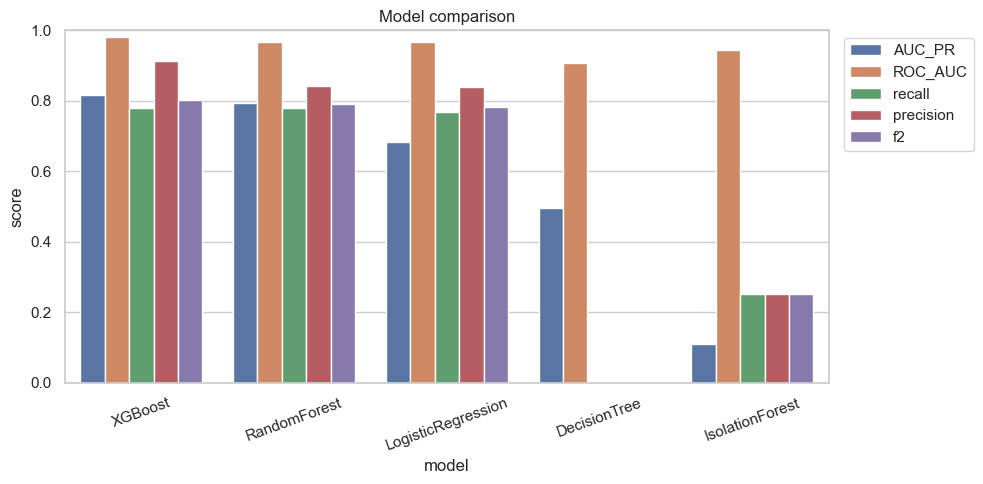

In [21]:
# Metric bars
plt.figure(figsize=(10, 5))
m = comparison.melt(id_vars="model", value_vars=["AUC_PR", "ROC_AUC", "recall", "precision", "f2"],
                    var_name="metric", value_name="score")
sns.barplot(data=m, x="model", y="score", hue="metric")
plt.xticks(rotation=20); plt.title("Model comparison"); plt.ylim(0, 1)
plt.legend(bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

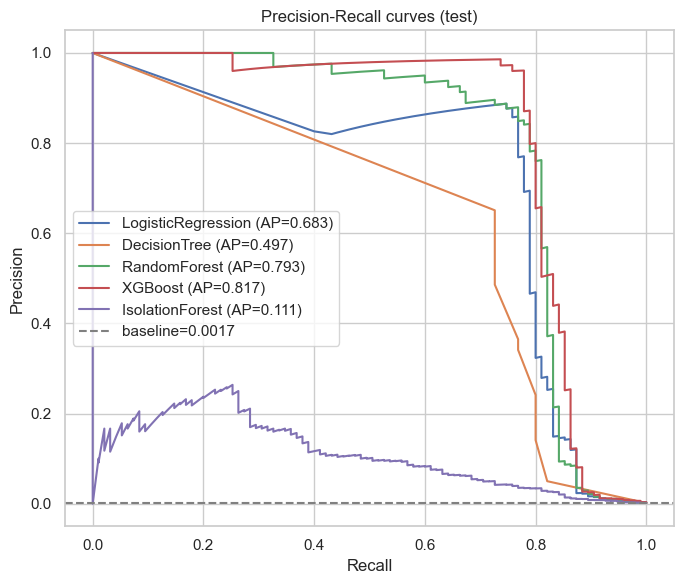

In [22]:
# Overlaid precision-recall curves (the right curve for imbalance)
plt.figure(figsize=(7, 6))
for name, s in test_scores.items():
    prec, rec, _ = precision_recall_curve(y_test, s)
    ap = average_precision_score(y_test, s)
    plt.plot(rec, prec, label=f"{name} (AP={ap:.3f})")
plt.axhline(y_test.mean(), ls="--", c="grey", label=f"baseline={y_test.mean():.4f}")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.title("Precision-Recall curves (test)"); plt.legend(); plt.tight_layout(); plt.show()

### Confusion matrix of the best model
Translate the winner into caught vs missed fraud and false alarms — the business view.

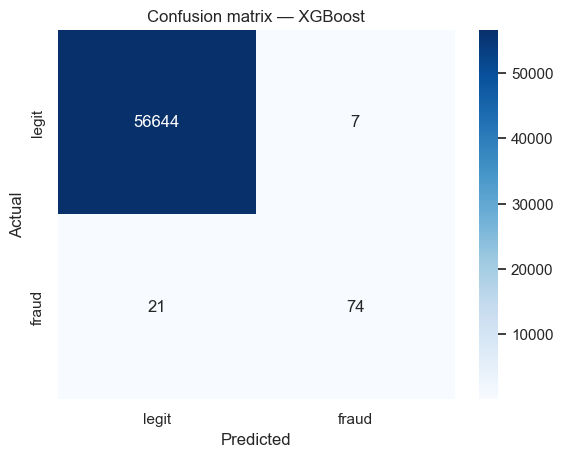

              precision    recall  f1-score   support

           0     0.9996    0.9999    0.9998     56651
           1     0.9136    0.7789    0.8409        95

    accuracy                         0.9995     56746
   macro avg     0.9566    0.8894    0.9203     56746
weighted avg     0.9995    0.9995    0.9995     56746



In [23]:
best_name = comparison.iloc[0]["model"]
best_thr  = comparison.iloc[0]["threshold"]
y_pred_best = (test_scores[best_name] >= best_thr).astype(int)

cm = confusion_matrix(y_test, y_pred_best)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["legit", "fraud"], yticklabels=["legit", "fraud"])
plt.title(f"Confusion matrix — {best_name}"); plt.ylabel("Actual"); plt.xlabel("Predicted")
plt.show()
print(classification_report(y_test, y_pred_best, digits=4))

## 7. (Optional) SMOTE done the leak-free way
Only run if `imbalanced-learn` is installed (`pip install imbalanced-learn`). SMOTE is placed
**inside** an imblearn `Pipeline`, so oversampling happens on each training fold only — never
on the test set.

In [25]:
try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE

    smote_rf = ImbPipeline([
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=12,
                                       n_jobs=-1, random_state=RANDOM_STATE)),
    ])
    oof = cross_val_predict(smote_rf, X_train, y_train, cv=skf,
                            method="predict_proba", n_jobs=-1)[:, 1]
    thr, _ = best_threshold(y_train, oof, beta=2.0)
    smote_rf.fit(X_train, y_train)
    s = smote_rf.predict_proba(X_test)[:, 1]
    print(evaluate("RandomForest+SMOTE", y_test, s, thr))
except ImportError:
    print("imbalanced-learn not installed (optional). Skipping SMOTE.")

{'model': 'RandomForest+SMOTE', 'AUC_PR': 0.7893646927989642, 'ROC_AUC': 0.9799533431379016, 'precision': 0.8275862068965517, 'recall': 0.7578947368421053, 'f1': 0.7912087912087912, 'f2': 0.7708779443254818, 'threshold': 0.5896680241971883, 'tn': np.int64(56636), 'fp': np.int64(15), 'fn': np.int64(23), 'tp': np.int64(72)}


## 8. Reproducibility — save artifacts to `models/`
Saves every fitted model, the fitted scaler, the comparison table, and a config JSON
(params + chosen thresholds). Re-load later with `joblib.load`.

In [ ]:
for name, model in fitted.items():
    joblib.dump(model, f"models/{name}.joblib")
joblib.dump(scaler, "models/scaler.joblib")

comparison.to_csv("models/metrics_comparison.csv", index=False)

config = {
    "random_state": RANDOM_STATE,
    "features": list(X_train.columns),
    "scaled_columns": to_scale,
    "thresholds": {r["model"]: r["threshold"] for r in results},
    "params": {name: model.get_params() for name, model in fitted.items()},
}
with open("models/configs.json", "w") as f:
    json.dump(config, f, indent=2, default=str)

print("Saved:", os.listdir("models"))